# 01 - Simple Linear Regression from Scratch

## Aim
Implement **Simple Linear Regression from scratch** using the least-squares method. The model will be derived from the training data instead of using a machine-learning library.

### Model used
For one predictor, the regression equation is


**ŷ = β₀ + β₁x**

where β₁ is the slope and β₀ is the intercept. The least-squares estimates are obtained by minimizing the sum of squared errors.

## 1. Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Read the dataset
The file `P176.txt` contains one input variable (`X`) and one continuous response (`Y`).

In [2]:
data = pd.read_csv("datasets/P176.txt", sep="\t")
data.head()

,X,Y
0,294,30
1,247,32
2,267,37
3,358,44
4,423,47


In [3]:
print("Rows and columns:", data.shape)
print("\nColumn names:", data.columns.tolist())

Rows and columns: (27, 2)

Column names: ['X', 'Y']


## 3. Separate predictor and target

In [4]:
x = data["X"].to_numpy(dtype=float)
y = data["Y"].to_numpy(dtype=float)

print("First five X values:", x[:5])
print("First five Y values:", y[:5])

First five X values: [294. 247. 267. 358. 423.]
First five Y values: [30. 32. 37. 44. 47.]


## 4. Calculate the least-squares coefficients

In [5]:
n = len(x)

slope = (n * np.sum(x * y) - np.sum(x) * np.sum(y)) / (n * np.sum(x**2) - np.sum(x)**2)
intercept = np.mean(y) - slope * np.mean(x)

print(f"Slope (β₁)      = {slope:.6f}")
print(f"Intercept (β₀)  = {intercept:.6f}")

Slope (β₁)      = 0.105361
Intercept (β₀)  = 14.448059


## 5. Form the regression equation

In [6]:
print(f"Estimated model: y = {intercept:.4f} + ({slope:.4f})x")

Estimated model: y = 14.4481 + (0.1054)x


## 6. Generate fitted values

In [7]:
predicted = intercept + slope * x
comparison = pd.DataFrame({"Observed": y, "Predicted": predicted})
comparison.head(10)

,Observed,Predicted
0,30.0,45.424220
1,32.0,40.472249
2,37.0,42.579471
3,44.0,52.167330
4,47.0,59.015801
5,49.0,47.215359
6,56.0,61.860551
7,62.0,70.710883
8,68.0,60.596218
9,78.0,87.884741


## 7. Measure the fitting error

In [8]:
errors = y - predicted
mse = np.mean(errors**2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(errors))

print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"MAE  = {mae:.4f}")

MSE  = 437.1876
RMSE = 20.9090
MAE  = 16.1397


## 8. Plot the regression line

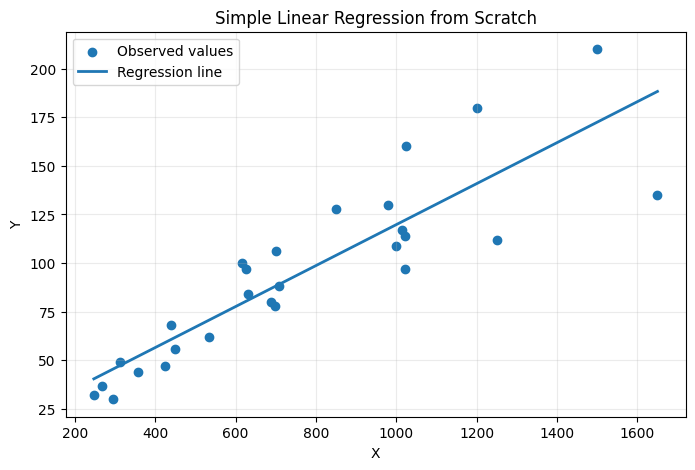

In [9]:
order = np.argsort(x)
plt.figure(figsize=(8, 5))
plt.scatter(x, y, label="Observed values")
plt.plot(x[order], predicted[order], linewidth=2, label="Regression line")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression from Scratch")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Conclusion
The slope and intercept were calculated directly from the least-squares formulas. The fitted line can now be used to estimate the response for a new value of `X`.